<a href="https://colab.research.google.com/github/sen-soumya/Optical-communication/blob/main/Carrier%20Phase%20Recovery%20(CPR)%20for%20Coherent%20Optical%20Receivers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Imports and Setup

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

### 2. Coherent Optical Channel Simulator

In [2]:
def generate_coherent_data(num_symbols=10000, snr_db=18, linewidth_hz=500e3, symbol_rate_baud=32e9, window_size=11):
    """
    Generates 16-QAM symbols corrupted by Additive White Gaussian Noise (AWGN)
    and Laser Phase Noise modeled as a Wiener process.
    """
    # 1. Generate standard, normalized 16-QAM constellation points
    points = np.array([-3, -1, 1, 3])
    x, y = np.meshgrid(points, points)
    constellation = (x + 1j * y) / np.sqrt(10)

    # Generate random symbols
    random_indices = np.random.choice(16, num_symbols)
    tx_symbols = constellation.flatten()[random_indices]

    # 2. Add AWGN
    snr_linear = 10 ** (snr_db / 10)
    noise_variance = 1.0 / snr_linear
    noise = np.sqrt(noise_variance / 2) * (np.random.normal(size=num_symbols) + 1j * np.random.normal(size=num_symbols))
    rx_awgn = tx_symbols + noise

    # 3. Add Laser Phase Noise (Random Walk)
    t_s = 1.0 / symbol_rate_baud
    phase_variance = 2 * np.pi * linewidth_hz * t_s
    phase_steps = np.random.normal(0, np.sqrt(phase_variance), num_symbols)
    phase_noise = np.cumsum(phase_steps)

    # Apply phase rotation
    rx_symbols = rx_awgn * np.exp(1j * phase_noise)

    # 4. Create sliding-window training targets
    X_data = []
    Y_data = []
    half_win = window_size // 2

    for i in range(half_win, num_symbols - half_win):
        window = rx_symbols[i - half_win : i + half_win + 1]
        # Split complex numbers into two parallel real-valued channels (I & Q)
        features = np.stack([np.real(window), np.imag(window)], axis=0)
        X_data.append(features)
        Y_data.append(phase_noise[i])

    return (
        torch.tensor(np.array(X_data), dtype=torch.float32),
        torch.tensor(np.array(Y_data), dtype=torch.float32).unsqueeze(1),
        rx_symbols,
        tx_symbols
    )

### 3. CNN Carrier Phase Recovery (CPR) Network Design

In [3]:
class CNNPhaseRegressor(nn.Module):
    """
    A 1D-CNN designed to model temporal relationships and phase shifts
    over a sliding window of received optical symbols.
    """
    def __init__(self, window_size=11):
        super(CNNPhaseRegressor, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels=2, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Flatten()
        )
        self.fc = nn.Sequential(
            nn.Linear(64 * window_size, 64),
            nn.ReLU(),
            nn.Linear(64, 1) # Predicts absolute phase angle deviation in radians
        )

    def forward(self, x):
        features = self.conv(x)
        return self.fc(features)

### 4. Hyperparameters and Experiment Setup

In [4]:
# Common configuration
linewidths_to_test = [100e3, 500e3, 2e6]  # 100 kHz (DFB), 500 kHz, 2 MHz (VCSEL)
window_size = 15
results_constellations = {}

### 5. Training and Evaluation Sweep

In [5]:
print("🚀 Starting Coherent ML-CPR Training Sweep...")

for lw in linewidths_to_test:
    print(f"\n⚡ Training model for Laser Linewidth: {lw/1e3:.0f} kHz")

    # Generate dataset split
    X_train, Y_train, _, _ = generate_coherent_data(num_symbols=12000, linewidth_hz=lw, window_size=window_size)
    X_test, Y_test, rx_raw, tx_raw = generate_coherent_data(num_symbols=3000, linewidth_hz=lw, window_size=window_size)

    loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=64, shuffle=True)

    model = CNNPhaseRegressor(window_size=window_size)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()

    # Training loop
    model.train()
    for epoch in range(15):
        for batch_x, batch_y in loader:
            optimizer.zero_grad()
            pred = model(batch_x)
            loss = criterion(pred, batch_y)
            loss.backward()
            optimizer.step()

    # Evaluation
    model.eval()
    with torch.no_grad():
        predicted_phase = model(X_test).numpy().flatten()

    # Sync boundaries of the sliding window with original received series
    half_win = window_size // 2
    cropped_rx = rx_raw[half_win : len(rx_raw) - half_win]

    # Compensate the phase drift
    recovered_symbols = cropped_rx * np.exp(-1j * predicted_phase)
    results_constellations[lw] = (cropped_rx, recovered_symbols)

    final_mse = np.mean((predicted_phase - Y_test.numpy().flatten()) ** 2)
    print(f"✅ Complete. Estimation MSE: {final_mse:.5e} rad^2")

🚀 Starting Coherent ML-CPR Training Sweep...

⚡ Training model for Laser Linewidth: 100 kHz
✅ Complete. Estimation MSE: 4.28713e-02 rad^2

⚡ Training model for Laser Linewidth: 500 kHz
✅ Complete. Estimation MSE: 7.50839e-01 rad^2

⚡ Training model for Laser Linewidth: 2000 kHz
✅ Complete. Estimation MSE: 5.77689e-01 rad^2


### 6. Visualize Phase Recovery Results

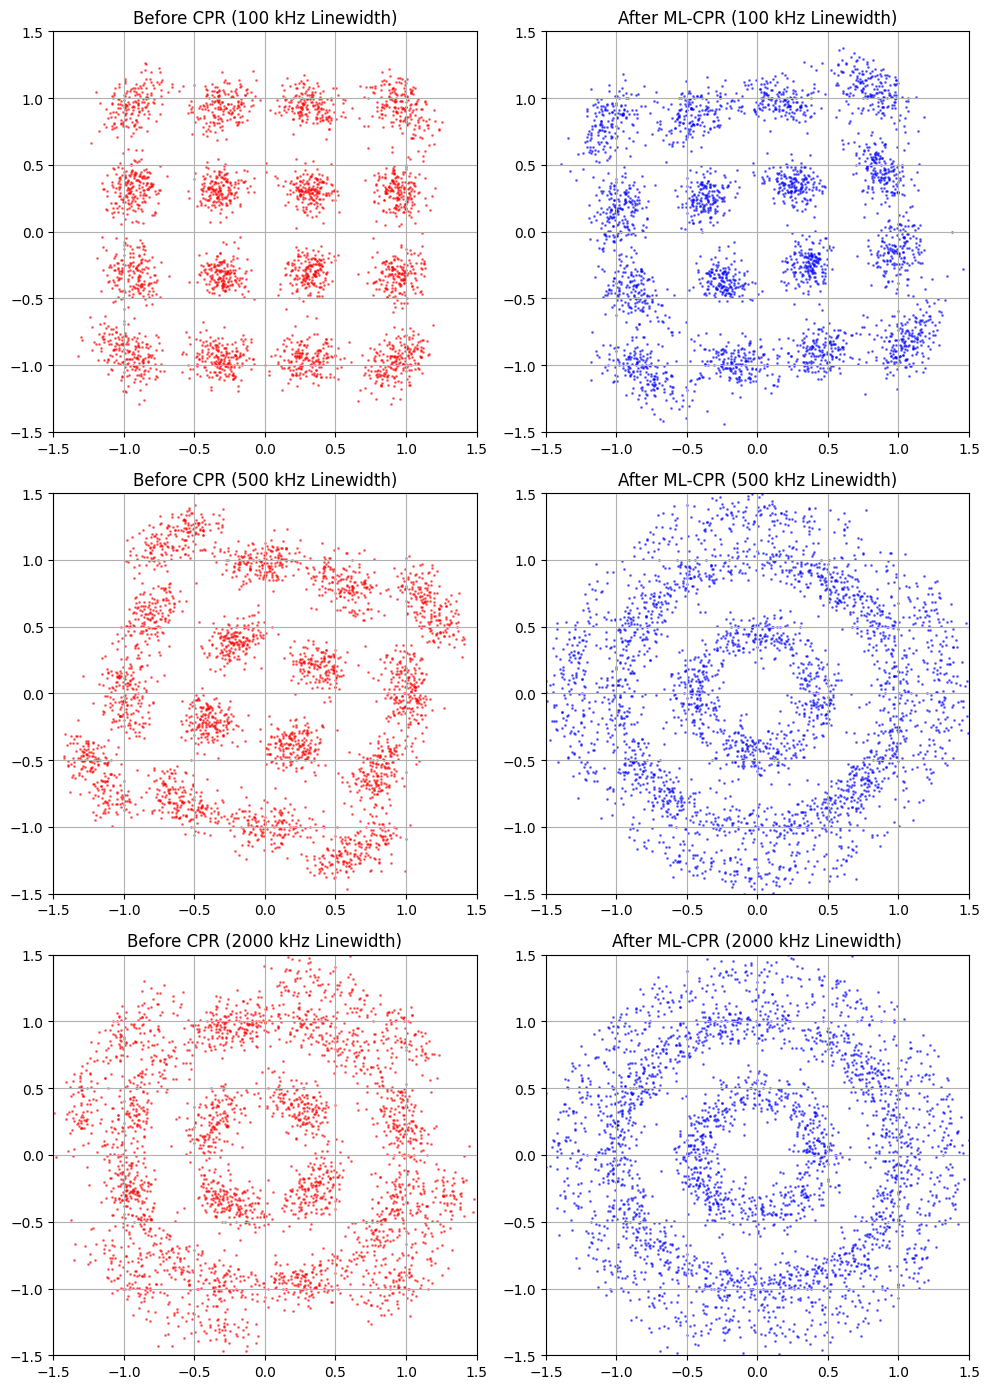

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(10, 14))

for idx, lw in enumerate(linewidths_to_test):
    rx_corrupted, rx_recovered = results_constellations[lw]

    # Left Column: Corrupted signal
    axes[idx, 0].scatter(np.real(rx_corrupted), np.imag(rx_corrupted), s=1, color='red', alpha=0.5)
    axes[idx, 0].set_title(f"Before CPR ({lw/1e3:.0f} kHz Linewidth)")
    axes[idx, 0].set_xlim([-1.5, 1.5])
    axes[idx, 0].set_ylim([-1.5, 1.5])
    axes[idx, 0].grid(True)

    # Right Column: Recovered signal
    axes[idx, 1].scatter(np.real(rx_recovered), np.imag(rx_recovered), s=1, color='blue', alpha=0.5)
    axes[idx, 1].set_title(f"After ML-CPR ({lw/1e3:.0f} kHz Linewidth)")
    axes[idx, 1].set_xlim([-1.5, 1.5])
    axes[idx, 1].set_ylim([-1.5, 1.5])
    axes[idx, 1].grid(True)

plt.tight_layout()
plt.show()